In [103]:
import numpy as np
from matplotlib import pyplot as plt
import cv2 as cv

# Aufgabe 1

In [104]:
house = cv.imread("/home/farouk/Uni/3. Semester/Bildverarbeitung/Bilder/GruenesHaus.jpg")
hl = cv.imread("/home/farouk/Uni/3. Semester/Bildverarbeitung/Bilder/HL-L.jpg")
gray_house= cv.cvtColor(house, cv.COLOR_BGR2GRAY)
gray_hl= cv.cvtColor(hl, cv.COLOR_BGR2GRAY)

In [105]:
def show_image(img, title):
    plt.imshow(img, cmap='gray')
    plt.title(title)
    plt.axis('off')
    plt.show()

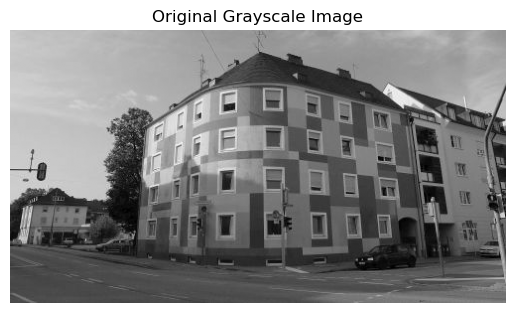

In [106]:
show_image(gray_house, "Original Grayscale Image")

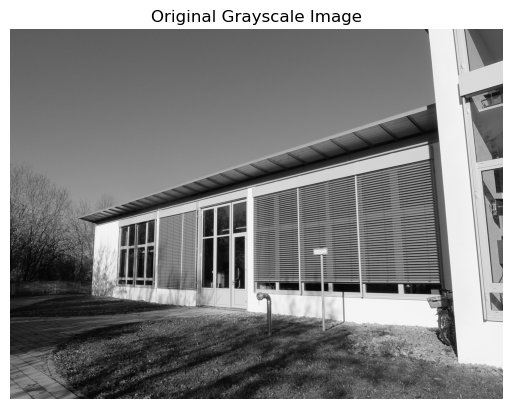

In [107]:
show_image(gray_hl, "Original Grayscale Image")

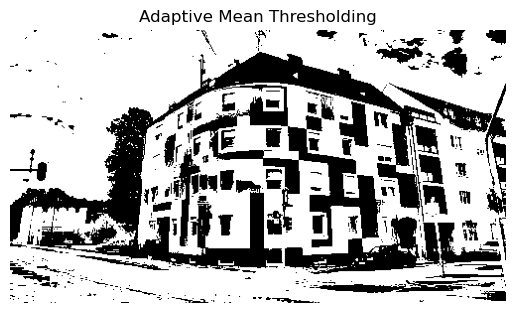

CPU times: user 77.2 ms, sys: 65 μs, total: 77.3 ms
Wall time: 83.5 ms


In [108]:
%%time
thresh_mean_house = cv.adaptiveThreshold(
    gray_house, 255,
    cv.ADAPTIVE_THRESH_MEAN_C,
    cv.THRESH_BINARY,
    55, 5
)

show_image(thresh_mean_house, "Adaptive Mean Thresholding")

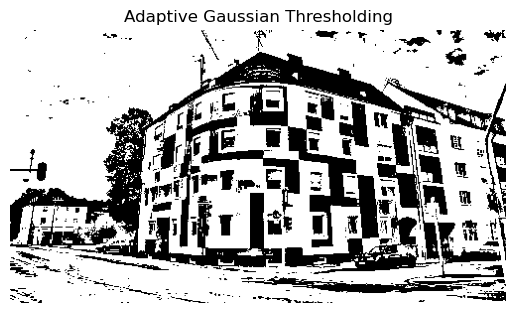

CPU times: user 66.6 ms, sys: 835 μs, total: 67.5 ms
Wall time: 71.7 ms


In [109]:
%%time
thresh_gauss_house = cv.adaptiveThreshold(
    gray_house, 255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY,
    55, 5
)
show_image(thresh_gauss_house, "Adaptive Gaussian Thresholding")

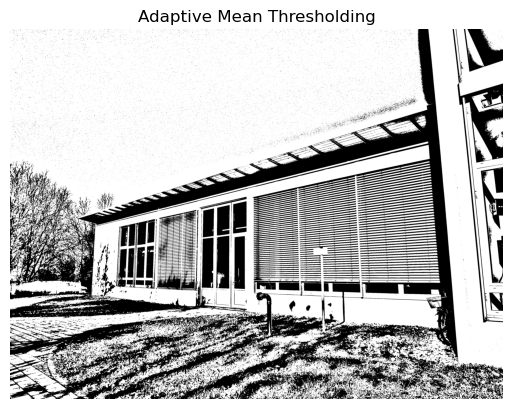

CPU times: user 817 ms, sys: 159 ms, total: 976 ms
Wall time: 1.07 s


In [110]:
%%time
thresh_mean_hl = cv.adaptiveThreshold(
    gray_hl, 255,
    cv.ADAPTIVE_THRESH_MEAN_C,
    cv.THRESH_BINARY,
    199, 5
)
show_image(thresh_mean_hl, "Adaptive Mean Thresholding")

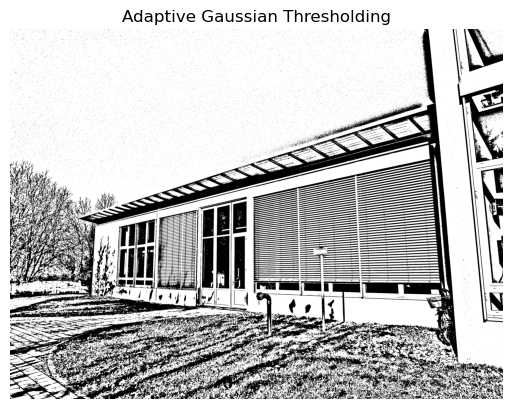

CPU times: user 1.13 s, sys: 605 ms, total: 1.74 s
Wall time: 1.42 s


In [111]:
%%time
thresh_gauss_hl = cv.adaptiveThreshold(
    gray_hl, 255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY,
    199, 5
)
show_image(thresh_gauss_hl, "Adaptive Gaussian Thresholding")

# Aufgabe 2

In [112]:
len(house.shape)

3

In [113]:
cv.integral(gray_house)

array([[       0,        0,        0, ...,        0,        0,        0],
       [       0,      197,      394, ...,    84391,    84536,    84682],
       [       0,      396,      792, ...,   168433,   168724,   169016],
       ...,
       [       0,    41059,    81853, ..., 15740421, 15772308, 15802959],
       [       0,    41134,    82003, ..., 15786316, 15818330, 15849104],
       [       0,    41207,    82149, ..., 15831789, 15863932, 15894831]],
      shape=(276, 501), dtype=int32)

In [114]:
import cv2
import numpy as np


mean, stddev = cv2.meanStdDev(gray_house)

print("Mean:", mean[0][0])
print("StdDev:", stddev[0][0])


Mean: 115.5987709090909
StdDev: 54.43789386028707


In [115]:
import cv2
import numpy as np
import time

def block_stddev_map(img, block_size):
    h, w = img.shape
    r = block_size // 2      # Radius um den Mittelpunkt

    output = np.zeros((h, w), dtype=np.float32)

    for y in range(h):
        for x in range(w):

            # Blockgrenzen berechnen
            y1 = max(0, y - r)
            y2 = min(h, y + r + 1)
            x1 = max(0, x - r)
            x2 = min(w, x + r + 1)

            block = img[y1:y2, x1:x2]

            # meanStdDev ausführen
            _, stddev = cv2.meanStdDev(block)

            # als float speichern
            output[y, x] = stddev[0][0]

    return output


In [116]:
for block_size in [7, 121]:
    start = time.time()
    result = block_stddev_map(gray_house, block_size)
    duration = time.time() - start

    print(f"Blockgröße {block_size}x{block_size}: {duration:.3f} Sekunden")

Blockgröße 7x7: 0.291 Sekunden
Blockgröße 121x121: 0.654 Sekunden


In [117]:
def compute_std(img, blocksize, name, save=False):

    if blocksize % 2 == 0:
        raise Exception("Die Blockgröße muss ungerade sein.")

    if len(img.shape) == 3: # Falls Farbbild, dann in Grauwertbild umwandeln
        img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    half_block = blocksize // 2

    height, width = img.shape # Größte Werte in jeder Dimension festlegen

    std = np.zeros((height, width), dtype = "float32") # Array, in dem die Ergebnisse gespeichert werden

    top_left = (0, 0)   # Koordianten der Eckpunkte festlegen 
    top_right = (0, width - 1)  # DA NUMPY IN DER FORM [Y, X] INDIZIERT SIND KOORDIANTEN VERTAUSCHT (NICHT [X, Y])!
    bottom_left = (height - 1, 0)
    bottom_right = (height - 1, width - 1)
    
    for y in range(height):  # Zeilenweise durch das Bild iterieren
        for x in range(width):

            y0 = max(0, y - half_block) # Größe des Blocks in X- und Y-Richtung ermitteln
            y1 = min(height, y + half_block + 1)

            x0 = max(0, x - half_block)
            x1 = min(width, x + half_block + 1)

            block = img[y0:y1, x0:x1]   # Block aus Bild ausschneiden
            _, stddev = cv.meanStdDev(block)    # Standardabweichung auf Block berechnen
            
    
            std[y, x] = stddev[0, 0]    # Wert der Standardabweichung in Array speichern
    
    if save:
        cv.imwrite(f"{name}_stddev_{blocksize}.tif", std)

    return std

In [118]:
%%time
stddev_7 = compute_std(house, 7, "house")

CPU times: user 330 ms, sys: 0 ns, total: 330 ms
Wall time: 288 ms


In [119]:
%%time
stddev_121 = compute_std(house, 121, "house")

CPU times: user 619 ms, sys: 0 ns, total: 619 ms
Wall time: 596 ms


In [120]:
ima_norma_7 = cv.normalize(stddev_7, None, 255, 0, cv.NORM_MINMAX, cv.CV_8UC1)
ima_norma_121 = cv.normalize(stddev_121, None, 255, 0, cv.NORM_MINMAX, cv.CV_8UC1)

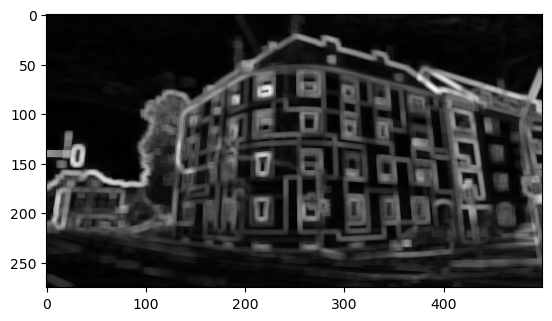

In [121]:
plt.imshow(ima_norma_7, cmap="gray")

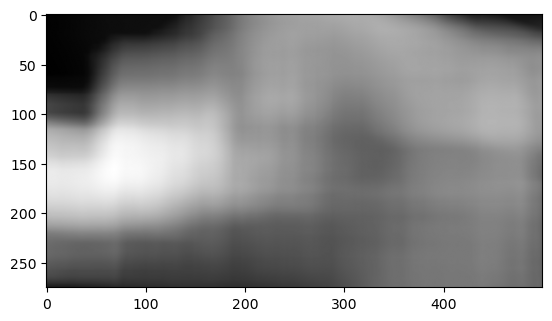

In [122]:
plt.imshow(ima_norma_121, cmap="gray")

## ASB Implementierung

In [123]:
def compute_std_asb(img, blocksize, name, save=False):

    if blocksize % 2 == 0:
        raise Exception("Die Blockgröße muss ungerade sein.")
    
    if len(img.shape) == 3: #Falls Farbbild in Grauwertbild umwandeln
        img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    img = img.astype("float32") #Dtype ändern (Quadrierung)

    height, width = img.shape # Größte Werte in jeder Dimension festlegen
    std = np.zeros((height, width), dtype = "float32") # Array, in dem die Ergebnisse gespeichert werden

    asb, sq_asb = cv.integral2(img)  #Integralbild & quadriertes Integralbild von img

    half_block = blocksize // 2

    for y in range(height):  # Zeilenweise durch das Bild iterieren
        for x in range(width):

            y0 = max(0, y - half_block) # Größe des Blocks in X- und Y-Richtung ermitteln
            y1 = min(height, y + half_block + 1)

            x0 = max(0, x - half_block)
            x1 = min(width, x + half_block + 1)

            n_pixel = (x1 - x0) * (y1- y0) #Anzahl der Pixel im Block berechnen

            sum_asb = asb[y1, x1] - asb[y0, x1] - asb[y1, x0] + asb[y0, x0] #Wert aus ASB holen
            avg_asb = sum_asb / n_pixel #Durchschnittswert berechnen

            sum_sq_asb = sq_asb[y1, x1] - sq_asb[y0, x1] - sq_asb[y1, x0] + sq_asb[y0, x0] #Wert aus quadr. ASB holen
            ev_sq_asb = sum_sq_asb / n_pixel    #Erwartungswert berechnen

            stddev = (ev_sq_asb - avg_asb**2)**0.5 #Standardabweichung aus Erwartungswert & Durchschnitt

            std[y, x] = stddev 
    
    if save:
        cv.imwrite(f"{name}_stddev_ASB_{blocksize}.tif", std)

    return std

In [124]:
%%time
stddev_7_ASB = compute_std_asb(house, 7, "house")

CPU times: user 266 ms, sys: 0 ns, total: 266 ms
Wall time: 199 ms


In [125]:
%%time
stddev_121_ASB = compute_std_asb(house, 121, "house")

CPU times: user 257 ms, sys: 0 ns, total: 257 ms
Wall time: 203 ms


In [126]:
ima_norma_7_ASB = cv.normalize(stddev_7_ASB, None, 255, 0, cv.NORM_MINMAX, cv.CV_8UC1)
ima_norma_121_ASB = cv.normalize(stddev_121_ASB, None, 255, 0, cv.NORM_MINMAX, cv.CV_8UC1)

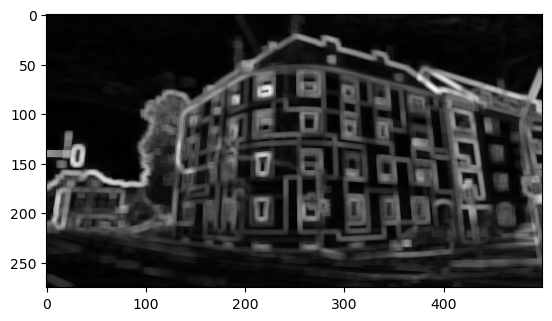

In [127]:
plt.imshow(ima_norma_7_ASB, cmap="gray")

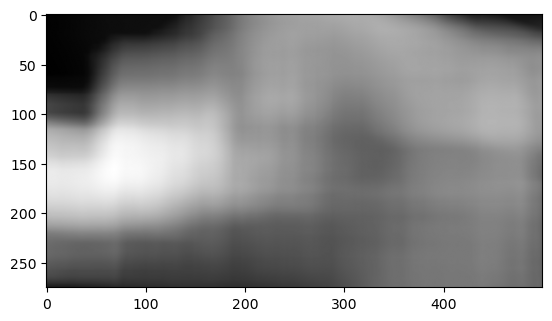

In [128]:
plt.imshow(ima_norma_121_ASB, cmap="gray")

In [129]:
def red_stddev(stddev, img, name, threshold, save=False):

    height, width = stddev.shape

    for y in range(height):
        for x in range(width):

            if stddev[y, x] > 50:
                img[y, x, 0] = 0
                img[y, x, 1] = 0
                img[y, x, 2] = 255

    if save:
        cv.imwrite(f"{name}_stddev>{threshold}_highlighted.tif", img) 

    return img

In [130]:
red_stddev(stddev_7_ASB, house, "house", 50, True)

array([[[225, 199, 183],
        [225, 199, 183],
        [223, 197, 181],
        ...,
        [193, 151, 114],
        [193, 151, 114],
        [194, 152, 115]],

       [[227, 201, 185],
        [227, 201, 185],
        [226, 200, 184],
        ...,
        [193, 151, 114],
        [194, 152, 115],
        [194, 152, 115]],

       [[229, 203, 187],
        [229, 203, 187],
        [229, 203, 187],
        ...,
        [194, 152, 115],
        [194, 152, 115],
        [194, 152, 115]],

       ...,

       [[ 88,  76,  70],
        [ 88,  76,  70],
        [ 89,  77,  71],
        ...,
        [117, 118, 122],
        [117, 118, 122],
        [112, 113, 117]],

       [[ 87,  75,  69],
        [ 87,  75,  69],
        [ 87,  75,  69],
        ...,
        [125, 126, 130],
        [125, 126, 130],
        [121, 122, 126]],

       [[ 85,  73,  67],
        [ 85,  73,  67],
        [ 85,  73,  67],
        ...,
        [127, 128, 132],
        [127, 128, 132],
        [123, 124, 128]]